In [1]:
import os
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter

import torch
import torch.nn as nn
import torch.nn.functional as F
import optuna

from PINN_SEIR import PINN_with_params, gradients, loss_fn_params, get_region_dates

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')

SEED = 555
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Устройство вычислений: {device}")



Устройство вычислений: cuda


c:\Users\Yascher\Desktop\Science\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
N_POP = 200.0          # Масштаб популяции внутри PINN
POP_TOTAL = 2_780_292  # Население Новосибирской области
DISEASE_DURATION = 10  # Длительность болезни для скользящей суммы (дней)

df_nsk = pd.read_csv('I_data.csv')
date_col = 'Date' if 'Date' in df_nsk.columns else 'Data'

start_idx, end_idx = 44, 1007
df_slice = df_nsk.iloc[start_idx:end_idx].copy().reset_index(drop=True)
dates_nsk = pd.to_datetime(df_slice[date_col].values)

I_raw = df_slice['new_diagnoses'].fillna(0).to_numpy(dtype=float)

# 1) Сглаживание 7-дневным окном
cases_smooth = pd.Series(I_raw).rolling(window=7, min_periods=1, center=True).mean().to_numpy()

# 2) Скользящая сумма за 10 дней
I_window_sum = pd.Series(cases_smooth).rolling(window=DISEASE_DURATION, min_periods=1).sum().to_numpy()
I_window_sum = np.maximum(I_window_sum, 1.0)

I_data = (I_window_sum[:, None] / POP_TOTAL) * N_POP
T = len(I_data)
t_days = np.arange(T, dtype=float)

print(f"Загружено {T} дней: {dates_nsk[0].date()} — {dates_nsk[-1].date()}")
print(f"Пик скользящей суммы (10 дней): {I_window_sum.max():.0f} чел.")
print(f"Пик на графике: {(I_window_sum).max():.0f}")

Загружено 963 дней: 2020-04-25 — 2022-12-13
Пик скользящей суммы (10 дней): 52707 чел.
Пик на графике: 52707


In [3]:
# Инициализация сети
model_pinn = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

t_norm_all = np.linspace(-1.0, 1.0, T)[:, None]
t_data_tensor = torch.tensor(t_norm_all, dtype=torch.float32, device=device)
I_data_tensor = torch.tensor(I_data, dtype=torch.float32, device=device)
t_colloc = (2.0 * torch.rand(3000, 1, device=device) - 1.0)

I0_val = float(I_data[0, 0])
I0_t = torch.tensor([[I0_val]], dtype=torch.float32, device=device)
R0_t = torch.tensor([[0.0]], dtype=torch.float32, device=device)
S0_t = torch.tensor([[N_POP - 4.0 * I0_val]], dtype=torch.float32, device=device)

loss_weights = (7.155, 4.459, 0.977, 24.929, 24.655, 4.555, 30.551, 85.0, 2.998, 4.547)

TRAIN_EPOCHS = 50000

lr_init = 1e-3

optimizer_pinn = torch.optim.Adam(model_pinn.parameters(), lr=lr_init, weight_decay=1e-5)
scheduler_pinn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_pinn, mode='min', factor=0.5, patience=500, min_lr=1e-6
)

for epoch in range(TRAIN_EPOCHS + 1):
    model_pinn.train()
    optimizer_pinn.zero_grad()
    loss, l_data = loss_fn_params(
        model_pinn, t_colloc, t_data_tensor, I_data_tensor, S0_t, I0_t, R0_t, loss_weights
    )
    loss.backward()
    optimizer_pinn.step()
    scheduler_pinn.step(loss.detach())
    
    if epoch % 2000 == 0:
        print(f"  [PINN] Epoch {epoch:5d} | Loss: {loss.item():.4f} | Data Loss: {l_data:.5f}")

  [PINN] Epoch     0 | Loss: 55952376.0000 | Data Loss: 46.37043
  [PINN] Epoch  2000 | Loss: 206.4960 | Data Loss: 0.95438
  [PINN] Epoch  4000 | Loss: 126.3887 | Data Loss: 0.96843
  [PINN] Epoch  6000 | Loss: 123.2790 | Data Loss: 1.03459
  [PINN] Epoch  8000 | Loss: 122.7083 | Data Loss: 1.03420
  [PINN] Epoch 10000 | Loss: 122.0795 | Data Loss: 1.02898
  [PINN] Epoch 12000 | Loss: 66.7098 | Data Loss: 0.75754
  [PINN] Epoch 14000 | Loss: 62.7837 | Data Loss: 0.72142
  [PINN] Epoch 16000 | Loss: 29.5033 | Data Loss: 0.31822
  [PINN] Epoch 18000 | Loss: 10.7723 | Data Loss: 0.08502
  [PINN] Epoch 20000 | Loss: 7.1266 | Data Loss: 0.05184
  [PINN] Epoch 22000 | Loss: 4.9165 | Data Loss: 0.03372
  [PINN] Epoch 24000 | Loss: 3.9023 | Data Loss: 0.02636
  [PINN] Epoch 26000 | Loss: 3.7545 | Data Loss: 0.02261
  [PINN] Epoch 28000 | Loss: 4.0895 | Data Loss: 0.01993
  [PINN] Epoch 30000 | Loss: 10.5348 | Data Loss: 0.01811
  [PINN] Epoch 32000 | Loss: 2.6742 | Data Loss: 0.01437
  [PINN]

In [4]:
optimizer_lbfgs = torch.optim.LBFGS(
    model_pinn.parameters(),
    lr=0.8,
    max_iter=1500,
    max_eval=2000,
    history_size=50,
    tolerance_grad=1e-7,
    tolerance_change=1e-9,
    line_search_fn="strong_wolfe"
)

eval_count = 0
best_lbfgs_eval = -1

def closure():
  global eval_count, best_test_loss, best_model_weights, best_lbfgs_eval

  optimizer_lbfgs.zero_grad()
  loss, loss_data = loss_fn_params(model_pinn, t_colloc, t_data_tensor, I_data_tensor, S0_t, I0_t, R0_t, loss_weights)
  loss.backward()

  eval_count += 1

  return loss

for step in range(10):
  loss_value = optimizer_lbfgs.step(closure)
  if step % 2 == 0:
    print(f"BFGS step {step}: loss = {loss_value.item():.4e}")

print(f">>> L-BFGS успешно завершен за {eval_count} вычислений функции.")

BFGS step 0: loss = 1.7327e+00
BFGS step 2: loss = 1.4298e+00
BFGS step 4: loss = 1.3430e+00
BFGS step 6: loss = 1.2781e+00
BFGS step 8: loss = 1.2403e+00
>>> L-BFGS успешно завершен за 15745 вычислений функции.


In [5]:
t_test = torch.linspace(-1.0, 1.0, 300, device=device).reshape(-1, 1)
with torch.no_grad():
    E_p, I_p, R_p, beta_p, sigma_p, gamma_p, _ = model_pinn(t_test)
    _, I_pinn_direct, _, _, _, _, _ = model_pinn(t_data_tensor)
t_test_np = t_test.cpu().numpy().flatten()
beta_interp_pinn = interp1d(t_test_np, beta_p.cpu().numpy().flatten(), kind='linear', fill_value='extrapolate')
sigma_interp_pinn = interp1d(t_test_np, sigma_p.cpu().numpy().flatten(), kind='linear', fill_value='extrapolate')
gamma_interp_pinn = interp1d(t_test_np, gamma_p.cpu().numpy().flatten(), kind='linear', fill_value='extrapolate')

def sir_ode_pinn(t, y):
    S, E, I, R = y
    b = float(beta_interp_pinn(t)) / N_POP
    s = float(sigma_interp_pinn(t))
    g = float(gamma_interp_pinn(t))
    return [-b * S * I, b * S * I - s * E, s * E - g * I, g * I]

E0_found = 5.0 * torch.sigmoid(model_pinn.E0_raw).item()
S0_pinn = N_POP - I0_val - E0_found
sol_pinn = solve_ivp(sir_ode_pinn, (-1.0, 1.0), [S0_pinn, E0_found, I0_val, 0.0],
                     t_eval=t_norm_all.flatten(), rtol=1e-7, atol=1e-7)

I_pinn_people = sol_pinn.y[2] * (POP_TOTAL / N_POP)

In [6]:
def calc_metrics_table(y_true, y_pred):
    y_t_norm = y_true
    y_p_norm = y_pred
    mse_1e4 = np.mean((y_t_norm - y_p_norm) ** 2) * 1e-4
    rmse_people = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae_people = np.mean(np.abs(y_true - y_pred))
    return mse_1e4, rmse_people, mae_people


MSE · 10^4 (отн.): 6.599577714492931
RMSE: 256.8964327212998
MAE: 256.8964327212998


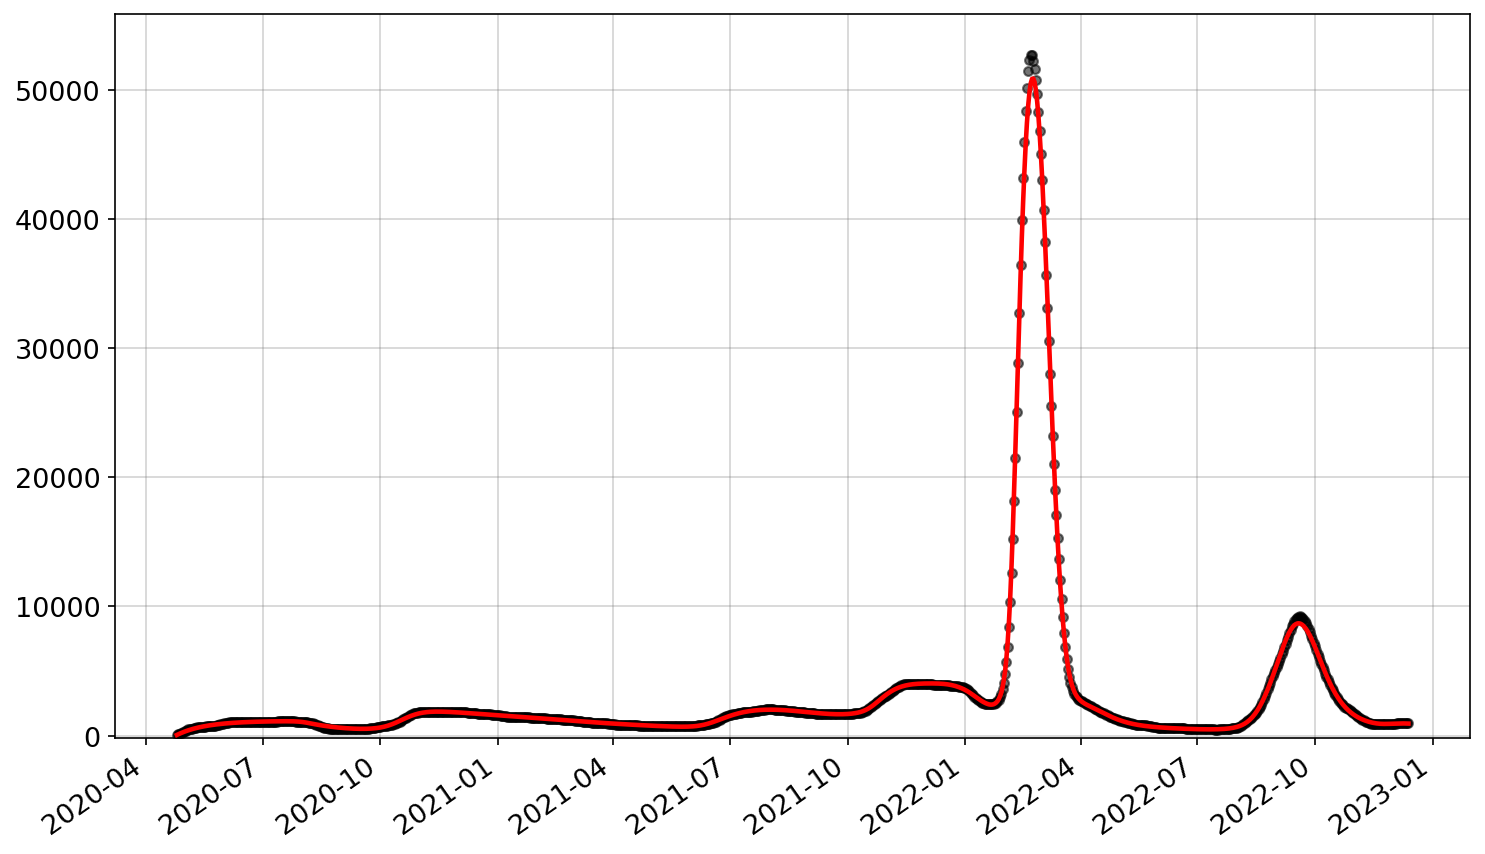

In [7]:
m_pinn   = calc_metrics_table(I_window_sum, I_pinn_people)

print("\n" + "=" * 60)
print(f'MSE · 10^4 (отн.): {m_pinn[0]}')
print(f'RMSE: {m_pinn[1]}')
print(f'MAE: {m_pinn[1]}')

fig, ax = plt.subplots(figsize=(10, 5.8), dpi=150)

ax.scatter(dates_nsk, I_window_sum, color='black', s=18, alpha=0.55, label='Данные', zorder=2)

ax.plot(dates_nsk, I_pinn_people, color='red', linestyle='-', linewidth=2.2, label='PINN', zorder=5)

ax.grid(True, linestyle='-', alpha=0.35, color='gray')
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.xticks(rotation=35, ha='right', fontsize=13)
plt.yticks(fontsize=13)
ax.set_ylim(bottom=-200, top=max(I_window_sum.max(), I_pinn_people.max()) * 1.06)

plt.tight_layout()
plt.savefig('seir_comparison_three_methods.png', dpi=200)
plt.show()

## Прогнозирование эпидемии

In [18]:
N_POP = 200
POP_TOTAL = 2780292

df = pd.read_csv('I_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df_slice = df.iloc[44:1007].copy().reset_index(drop=True)

dates_total = df_slice['Date'].to_numpy()
I_raw = df_slice['new_diagnoses'].fillna(0).to_numpy()
DISEASE_DURATION = 10  # дней

I_window_sum = pd.Series(I_raw).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_total = (I_window_sum / POP_TOTAL * N_POP)[:, None]
T_len = len(I_total)

train_ratio = 0.93
T_train = int(T_len * train_ratio)

days_norm = np.linspace(-1, 1, T_len)[:, None]
t_split = days_norm[T_train - 1, 0]

t_data_train = torch.tensor(days_norm[:T_train], dtype=torch.float32, device=device)
I_data_train = torch.tensor(I_total[:T_train], dtype=torch.float32, device=device)

t_data_test = torch.tensor(days_norm[T_train:], dtype=torch.float32, device=device)
I_data_test = torch.tensor(I_total[T_train:], dtype=torch.float32, device=device)

N_colloc = 3000
t_colloc = 2.0 * torch.rand(N_colloc, 1, device=device) - 1.0

I0_val = float(I_total[0].item())
I0 = torch.tensor([[I0_val]], dtype=torch.float32, device=device)
R0 = torch.tensor([[0.0]], dtype=torch.float32, device=device)
S0 = torch.tensor([[N_POP - 4.0 * I0_val]], dtype=torch.float32, device=device)

model_split = PINN_with_params(
    layers_state=[1, 128, 128, 128, 128, 3],
    layers_param=[1, 128, 128, 128, 3],
    N_POP=N_POP,
    T=T
).to(device)

weights_split = (7.15, 4.45, 0.98, 24.9, 24.6, 4.55, 30.5, 56.88, 3.0, 4.5)
optimizer = torch.optim.Adam(model_split.parameters(), lr=1e-3, weight_decay=1e-6)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=600)

history = {
    'epoch': [],
    'train_loss': [],
    'train_loss_data': [],
    'train_mse': [],
    'test_mse': [],
    'test_mae': [],
    'test_mape': []
}

EPOCHS = 70000
VAL_INTERVAL = 2000

best_test_loss = float('inf')
best_model_weights = None

print(f"{'Epoch':<8} | {'Total Loss':<12} | {'Tr DataLoss':<12} | {'Train MSE':<10} | {'Test MSE':<10} | {'Test MAE':<10} | {'Test MAPE':<10}")
print("-" * 85)

for epoch in range(EPOCHS + 1):
    model_split.train()
    optimizer.zero_grad()
    
    loss, loss_data = loss_fn_params(
        model_split, t_colloc, t_data_train, I_data_train, S0, I0, R0, weights=weights_split
    )
    loss.backward()
    optimizer.step()
    
    scheduler.step(loss.detach())
    
    if epoch % VAL_INTERVAL == 0:
        model_split.eval()
        with torch.no_grad():
            _, I_pred_tr, _, _, _, _, _ = model_split(t_data_train)
            _, I_pred_te, _, _, _, _, _ = model_split(t_data_test)
            
            y_tr_pred = I_pred_tr.cpu().numpy().flatten() / N_POP * POP_TOTAL
            y_tr_true = I_data_train.cpu().numpy().flatten() / N_POP * POP_TOTAL
            
            y_te_pred = I_pred_te.cpu().numpy().flatten() / N_POP * POP_TOTAL
            y_te_true = I_data_test.cpu().numpy().flatten() / N_POP * POP_TOTAL
            
            tr_mse = np.mean((y_tr_pred - y_tr_true) ** 2)
            te_mse = np.mean((y_te_pred - y_te_true) ** 2)
            te_mae = np.mean(np.abs(y_te_pred - y_te_true))
            te_mape = np.mean(np.abs((y_te_true - y_te_pred) / np.maximum(y_te_true, 1e-3))) * 100

            if te_mse < best_test_loss and epoch > 20000:
                best_test_loss = te_mse
                best_model_weights = copy.deepcopy(model_split.state_dict())
                best_epoch = epoch
            
            history['epoch'].append(epoch)
            history['train_loss'].append(loss.item())
            history['train_loss_data'].append(loss_data)
            history['train_mse'].append(tr_mse)
            history['test_mse'].append(te_mse)
            history['test_mae'].append(te_mae)
            history['test_mape'].append(te_mape)
            
            print(f"{epoch:<8d} | {loss.item():<12.4e} | {loss_data:<12.4e} | {tr_mse:<10.1f} | {te_mse:<10.1f} | {te_mae:<10.2f} | {te_mape:<9.2f}%")



Epoch    | Total Loss   | Tr DataLoss  | Train MSE  | Test MSE   | Test MAE   | Test MAPE 
-------------------------------------------------------------------------------------
0        | 5.8538e+07   | 4.6616e+01   | 1433859522560.0 | 1597521657856.0 | 1263921.25 | 97458.13 %
2000     | 2.0947e+02   | 1.0429e+00   | 59166980.0 | 2016497.6  | 1291.89    | 107.06   %
4000     | 1.0253e+02   | 1.0013e+00   | 62373888.0 | 1638886.9  | 891.34     | 45.51    %
6000     | 9.5168e+01   | 1.1355e+00   | 63275836.0 | 1855540.1  | 871.26     | 37.23    %
8000     | 9.1976e+01   | 1.1146e+00   | 63149352.0 | 1743309.2  | 893.49     | 42.92    %
10000    | 4.7722e+01   | 7.7756e-01   | 59179104.0 | 2725349.5  | 1520.45    | 131.69   %
12000    | 4.4581e+01   | 7.5528e-01   | 58369352.0 | 3632755.5  | 1761.85    | 156.72   %
14000    | 4.3759e+01   | 7.4639e-01   | 58245464.0 | 2937645.5  | 1584.97    | 138.82   %
16000    | 3.6401e+01   | 6.2437e-01   | 55957488.0 | 1378423.2  | 947.73     | 63.70

In [19]:
print("\n>>> [ЭТАП 2] Запуск L-BFGS...")

model_split.train()

optimizer_lbfgs = torch.optim.LBFGS(
    model_split.parameters(),
    lr=0.8,
    max_iter=1500,
    max_eval=2000,
    history_size=50,
    tolerance_grad=1e-7,
    tolerance_change=1e-9,
    line_search_fn="strong_wolfe"
)

eval_count = 0
best_lbfgs_eval = -1


def closure():
  global eval_count, best_test_loss, best_model_weights, best_lbfgs_eval

  optimizer_lbfgs.zero_grad()
  loss, loss_data = loss_fn_params(
      model_split,
      t_colloc,
      t_data_train,
      I_data_train,
      S0,
      I0,
      R0,
      weights=weights_split,
  )
  loss.backward()

  eval_count += 1

  if eval_count % 50 == 0:
    with torch.no_grad():
      _, I_pred_te, _, _, _, _, _ = model_split(t_data_test)

      y_te_pred = I_pred_te.cpu().numpy().flatten() / N_POP * POP_TOTAL
      y_te_true = I_data_test.cpu().numpy().flatten() / N_POP * POP_TOTAL

      te_mse_eval = float(np.mean((y_te_pred - y_te_true) ** 2))
      te_mae_eval = float(np.mean(np.abs(y_te_pred - y_te_true)))

      if te_mse_eval < best_test_loss:
        best_test_loss = te_mse_eval
        best_model_weights = copy.deepcopy(model_split.state_dict())
        best_lbfgs_eval = eval_count

    print(
        f"L-BFGS Eval {eval_count:4d} | Loss: {loss.item():.4e} | Train Data:"
        f" {loss_data:.4e} | Test MSE: {te_mse_eval:.1f} | Test MAE:"
        f" {te_mae_eval:.1f}"
    )

  return loss

for step in range(10):
  loss_value = optimizer_lbfgs.step(closure)
  if step % 2 == 0:
    print(f"BFGS step {step}: loss = {loss_value.item():.4e}")

print(f">>> L-BFGS успешно завершен за {eval_count} вычислений функции.")

if best_model_weights is not None:
  model_split.load_state_dict(best_model_weights)
  if best_lbfgs_eval != -1:
    print(
        f">>> Загружен чекпоинт, сохраненный в L-BFGS на eval {best_lbfgs_eval}"
        f" (Test MSE: {best_test_loss:.2f})"
    )
  else:
    print(
        ">>> Загружен чекпоинт с этапа Adam (в L-BFGS улучшений на тесте не"
        f" найдено, Test MSE: {best_test_loss:.2f})"
    )



>>> [ЭТАП 2] Запуск L-BFGS...
L-BFGS Eval   50 | Loss: 5.5324e-01 | Train Data: 4.9052e-03 | Test MSE: 33904112.0 | Test MAE: 5736.4
L-BFGS Eval  100 | Loss: 5.5059e-01 | Train Data: 4.8473e-03 | Test MSE: 33276172.0 | Test MAE: 5682.9
L-BFGS Eval  150 | Loss: 5.4676e-01 | Train Data: 4.7414e-03 | Test MSE: 33417246.0 | Test MAE: 5698.1
L-BFGS Eval  200 | Loss: 5.4214e-01 | Train Data: 4.6869e-03 | Test MSE: 32820830.0 | Test MAE: 5648.6
L-BFGS Eval  250 | Loss: 5.3714e-01 | Train Data: 4.5975e-03 | Test MSE: 32243852.0 | Test MAE: 5601.4
L-BFGS Eval  300 | Loss: 5.3358e-01 | Train Data: 4.5477e-03 | Test MSE: 31577734.0 | Test MAE: 5542.9
L-BFGS Eval  350 | Loss: 5.2947e-01 | Train Data: 4.5139e-03 | Test MSE: 30585392.0 | Test MAE: 5455.2
L-BFGS Eval  400 | Loss: 5.2565e-01 | Train Data: 4.4531e-03 | Test MSE: 29660420.0 | Test MAE: 5373.6
L-BFGS Eval  450 | Loss: 5.2283e-01 | Train Data: 4.4103e-03 | Test MSE: 28873172.0 | Test MAE: 5302.3
L-BFGS Eval  500 | Loss: 5.2005e-01 | Trai

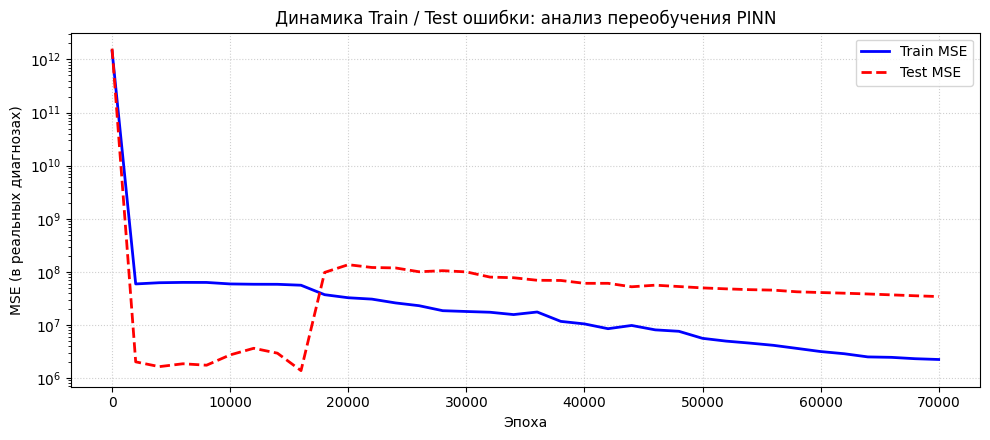

In [20]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))

ax1.plot(history['epoch'], history['train_mse'], color='blue', lw=2, label='Train MSE')
ax1.plot(history['epoch'], history['test_mse'], color='red', lw=2, linestyle='--', label='Test MSE')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('MSE (в реальных диагнозах)')
ax1.set_yscale('log')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')
ax1.set_title('Динамика Train / Test ошибки: анализ переобучения PINN')

plt.tight_layout()
plt.show()

Train MSE: 0.0021 | Test MSE: 0.0654


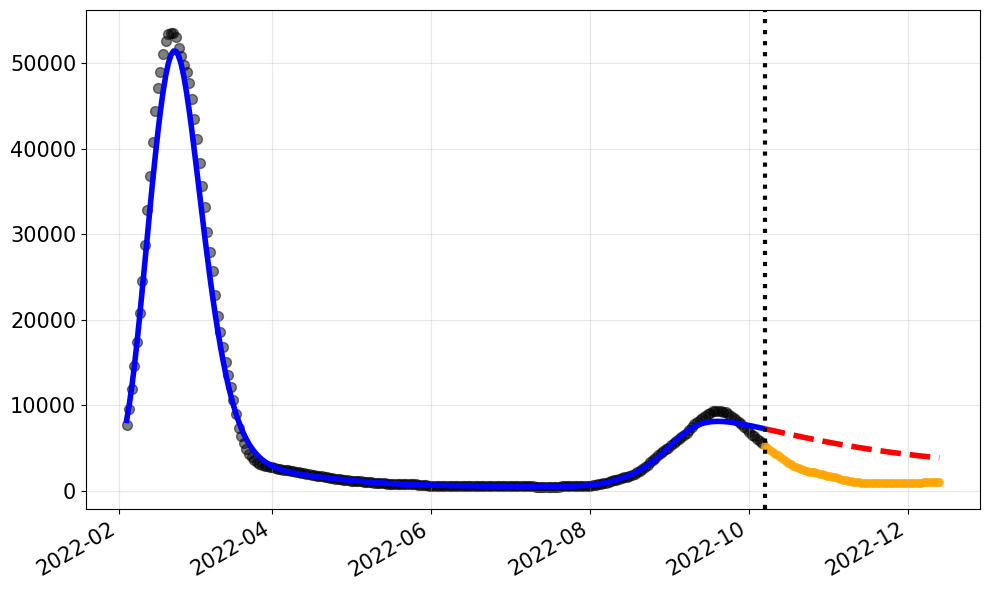

In [21]:
# 5. Оценка и график с датами на оси OX
model_split.eval()
t_eval_all = torch.tensor(days_norm, dtype=torch.float32, device=device)
with torch.no_grad():
    E_all, I_all, R_all, beta_all, sigma_all, gamma_all, _ = model_split(t_eval_all)
    I_pred = I_all.cpu().numpy().flatten()

mse_train = np.mean((I_pred[:T_train] - I_total[:T_train].flatten()) ** 2)
mse_test = np.mean((I_pred[T_train:] - I_total[T_train:].flatten()) ** 2)
print(f"Train MSE: {mse_train:.4f} | Test MSE: {mse_test:.4f}")


fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(dates_total[650:T_train], I_total[650:T_train]/N_POP*POP_TOTAL, color='black', s=50, alpha=0.5, label='I_data (Train)')
ax.scatter(dates_total[T_train:], I_total[T_train:]/N_POP*POP_TOTAL, color='orange', s=30, alpha=0.7, label='I_data (Validation/Test)')
ax.plot(dates_total[650:T_train], I_pred[650:T_train]/N_POP*POP_TOTAL, color='blue', linewidth=4, label='PINN Fit (Train)')
ax.plot(dates_total[T_train:], I_pred[T_train:]/N_POP*POP_TOTAL, color='red', linewidth=4, linestyle='--', label='PINN Test Forecast')

ax.axvline(dates_total[T_train], color='black', linestyle=':', linewidth=3, label='Train/Test Split')
# ax.set_title("Эксперимент 1: Валидация модели SEIR на тестовой выборке", fontsize=14)
# ax.set_ylabel("Infected Individuals (I)", fontsize=12)
ax.grid(True, alpha=0.3)

# Настройка оси дат
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()

# ax.legend(fontsize=11)
plt.tick_params(labelsize=15)
plt.tight_layout()
plt.show()

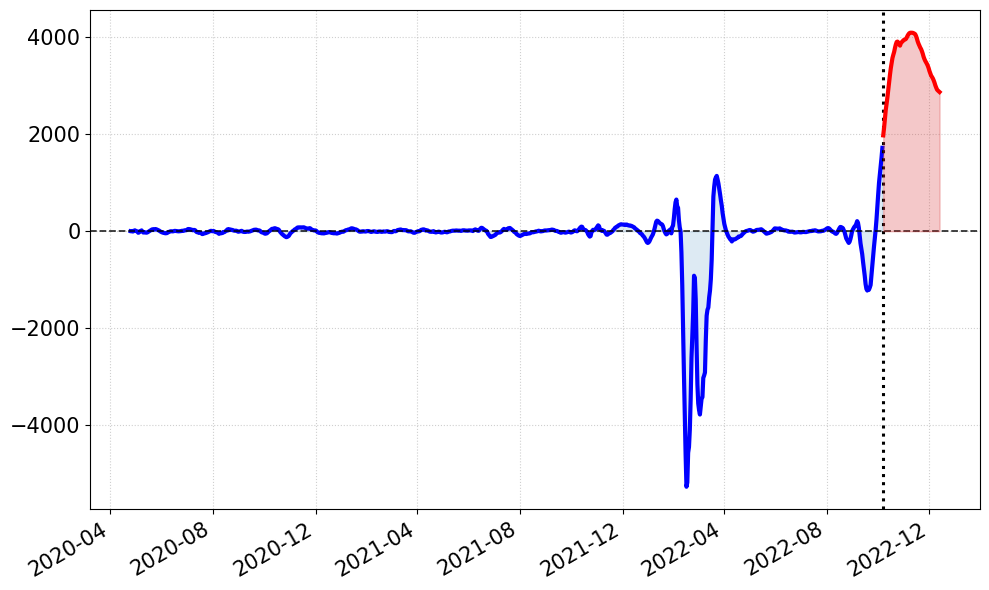

In [22]:
y_true = np.asarray(I_total).flatten() / N_POP * POP_TOTAL
y_pred = np.asarray(I_pred).flatten() / N_POP * POP_TOTAL

residuals = y_pred - y_true

res_train = residuals[:T_train]
dates_train = dates_total[:T_train]

res_test = residuals[T_train:]
dates_test = dates_total[T_train:]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    dates_train,
    res_train,
    color='blue',
    linewidth=3,
    label='Невязка $y_{pred} - y_{true}$ (Train)',
    zorder=2,
)
ax.fill_between(dates_train, res_train, 0, color='#1f77b4', alpha=0.15, zorder=1)

ax.plot(
    dates_test,
    res_test,
    color='red',
    linewidth=3.0,
    label='Невязка $y_{pred} - y_{true}$ (Test)',
    zorder=4,
)

ax.fill_between(dates_test, res_test, 0, color='#d62728', alpha=0.25, zorder=3)

ax.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=1.3,
    alpha=0.8,
    label='Нулевая ошибка ($y_{pred} = y_{true}$)',
)

ax.axvline(
    dates_total[T_train],
    color='black',
    linestyle=':',
    linewidth=2.2,
    label='Граница Train/Test',
)

ax.grid(True, linestyle=':', alpha=0.6)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()

plt.tick_params(labelsize=15)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model_split.eval()
t_eval_all = torch.tensor(days_norm, dtype=torch.float32, device=device)

with torch.no_grad():
    E_all, I_all, R_all, beta_all, sigma_all, gamma_all, _ = model_split(t_eval_all)
    
    # Извлечение состояний в масштабе исходных данных
    I_pred_scaled = I_all.cpu().numpy().flatten()
    
    # Перевод параметров в физические величины
    beta_np = beta_all.cpu().numpy().flatten() / T_len * 2  # физический бета
    sigma_np = sigma_all.cpu().numpy().flatten() / T_len * 2
    gamma_np = gamma_all.cpu().numpy().flatten() / T_len * 2
    
    # Вычисление R0(t) = beta(t) / gamma(t)
    R0_np = beta_np / (gamma_np + 1e-8)

# Истинные значения (в масштабе N_POP)
I_true = I_total.flatten()

# Разделение на train и test
y_train_true = I_true[:T_train]/N_POP*POP_TOTAL
y_train_pred = I_pred_scaled[:T_train]/N_POP*POP_TOTAL

y_test_true = I_true[T_train:]/N_POP*POP_TOTAL
y_test_pred = I_pred_scaled[T_train:]/N_POP*POP_TOTAL

# Функция вычисления полного набора метрик
def calc_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    # Защита от деления на 0 при вычислении MAPE (epsilon)
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-3))) * 100
    r2 = r2_score(y_true, y_pred)
    return mse, rmse, mae, mape, r2

mse_tr, rmse_tr, mae_tr, mape_tr, r2_tr = calc_metrics(y_train_true, y_train_pred)
mse_te, rmse_te, mae_te, mape_te, r2_te = calc_metrics(y_test_true, y_test_pred)

print("=" * 60)
print(f"{'Метрика':<15} | {'Train':<15} | {'Test / Forecast':<15}")
print("-" * 60)
print(f"{'MSE':<15} | {mse_tr:<15.4e} | {mse_te:<15.4e}")
print(f"{'RMSE':<15} | {rmse_tr:<15.4f} | {rmse_te:<15.4f}")
print(f"{'MAE':<15} | {mae_tr:<15.4f} | {mae_te:<15.4f}")
print(f"{'MAPE (%)':<15} | {mape_tr:<15.2f} | {mape_te:<15.2f}")
print(f"{'R² Score':<15} | {r2_tr:<15.4f} | {r2_te:<15.4f}")
print("=" * 60)

Метрика         | Train           | Test / Forecast
------------------------------------------------------------
MSE             | 4.0917e+05      | 1.2639e+07     
RMSE            | 639.6634        | 3555.0702      
MAE             | 186.3224        | 3517.0428      
MAPE (%)        | 3.35            | 275.63         
R² Score        | 0.9930          | -7.8273        
